# Walkthrough: from raw workbook to mechanistic results

This notebook retraces the analysis step by step with the project library
(`src/mice_protein`). It is a guided tour, not the pipeline: the authoritative numbers come from
`make reproduce` and live in `results/mechanisms/summary.json`.

**Steps:** 1. load and validate the data · 2. find the experimental unit · 3. check the technical
structure · 4. build mouse-level values · 5. score the learning signature · 6. gene dosage.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mice_protein import plotting as P
from mice_protein import signatures as S
from mice_protein.data import (CELLS, analysis_panel, duplicate_columns, load_data,
                               log2_animal_matrix)
from mice_protein.dosage import dosage_table
from mice_protein.qc import variance_components

%matplotlib inline
P.apply_style()
%config InlineBackend.figure_format = "retina"

## 1. Load and validate
`load_data` refuses to continue unless the workbook has 1,080 rows, 77 proteins, 72 animals with
15 rows each, and labels that never change within an animal.

In [2]:
raw = load_data(ROOT / "Data/Raw_Data/Data_Cortex_Nuclear.xls")
raw.groupby("class").agg(rows=("MouseID", "size"), mice=("AnimalID", "nunique"))

,rows,mice
class,,
c-CS-m,150,10
c-CS-s,135,9
c-SC-m,150,10
c-SC-s,135,9
t-CS-m,135,9
t-CS-s,105,7
t-SC-m,135,9
t-SC-s,135,9


## 2. The experimental unit is the mouse
Each mouse appears 15 times. Splitting rows at random would put the same mouse in training and
test data, so every analysis below uses **one value per mouse**. The workbook also contains an
exact duplicate column:

In [3]:
duplicate_columns(raw)

{'pS6_N': 'ARC_N'}

## 3. Technical structure
Most variance is between mice; within a mouse, most variance follows the inferred technical block
(rows 1–3, 4–6, …). Blocks are balanced across mice, so they cancel in mouse means.

icc            0.714023
block_share    0.823963
dtype: float64

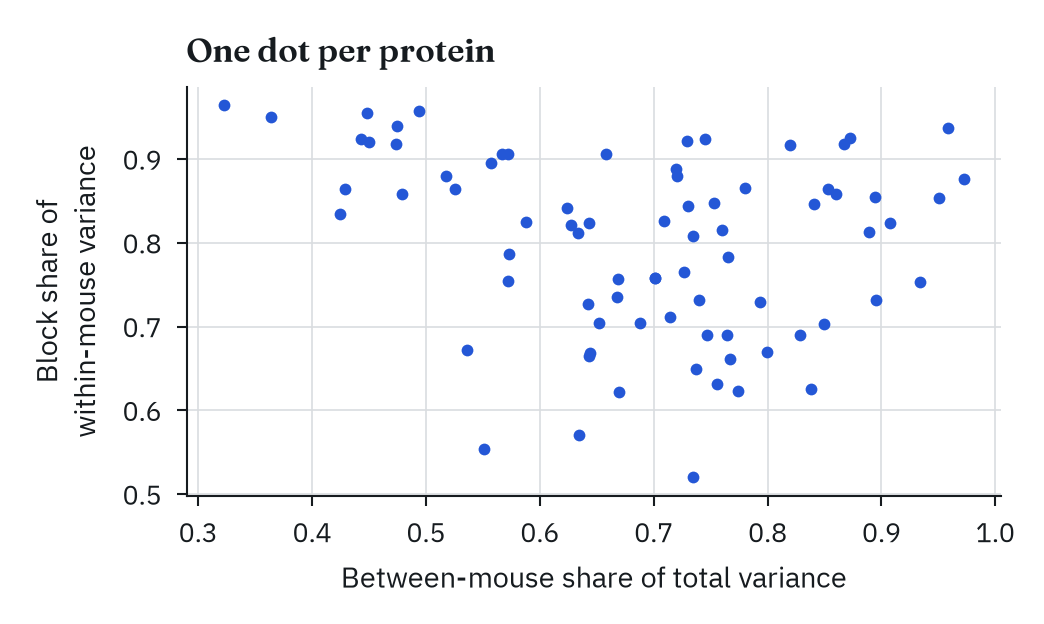

In [4]:
vc = variance_components(raw)
fig, ax = plt.subplots(figsize=(P.SINGLE, 45 * P.MM))
ax.scatter(vc.icc, vc.block_share, s=8, color=P.COBALT, lw=0)
ax.set(xlabel="Between-mouse share of total variance", ylabel="Block share of\nwithin-mouse variance")
ax.grid(axis="x")
P.title(ax, "One dot per protein")
vc[["icc", "block_share"]].median()

## 4. Mouse-level values
We average log₂ intensities within each mouse (a geometric mean), keep the 70 non-sparse,
non-duplicated proteins, and standardise each by its pooled within-cell SD.

In [5]:
values, labels = log2_animal_matrix(raw)
panel = analysis_panel(raw)
z = S.standardize(values[panel], labels["class"])
codes = labels["class"].map({c: k for k, c in enumerate(CELLS)}).to_numpy()
z.shape

(72, 70)

## 5. The learning signature
The reference axis is the CS − SC difference in control-saline mice. Every mouse is projected onto
it; mice that define the axis are scored on a leave-one-out version, so they cannot score
themselves. The response of each arm is expressed relative to control saline.

In [6]:
learning = S.learning_analysis(z, codes)
pd.DataFrame({"response (SD units)": learning.response, "relative to control saline": learning.relative}).round(2)

,response (SD units),relative to control saline
control saline,9.46,1.00
control memantine,7.98,0.84
Ts65Dn saline,6.34,0.67
Ts65Dn memantine,9.86,1.04


Confidence intervals and permutation p-values (thousands of resamples) are computed by
`scripts/mechanism_analysis.py`; see `results/mechanisms/summary.json` → `learning`.

## 6. Gene dosage
Proteins from triplicated genes would be 1.5× (log₂FC 0.58) under strict dosage. Estimates in
saline and memantine mice use disjoint animals, so they replicate each other.

In [7]:
dos = dosage_table(values, labels["class"])
dos[dos.dosage_class != "Not on HSA21"][["protein", "dosage_class", "estimate_saline", "estimate_memantine"]].round(2)

,protein,dosage_class,estimate_saline,estimate_memantine
0,ADARB1_N,"HSA21 ortholog, disomic",-0.12,-0.04
3,APP_N,Triplicated in Ts65Dn,0.23,0.23
16,DSCR1_N,Triplicated in Ts65Dn,-0.03,0.01
17,DYRK1A_N,Triplicated in Ts65Dn,0.18,0.32
29,ITSN1_N,Triplicated in Ts65Dn,0.21,0.34
43,RRP1_N,"HSA21 ortholog, disomic",0.08,-0.01
48,SOD1_N,Triplicated in Ts65Dn,-0.15,0.13
50,TIAM1_N,Triplicated in Ts65Dn,0.07,0.05


## Where to go next
* Full results and figures: `paper/main.pdf`
* Plain-language summary: `report/study_report.pdf`
* Every statistical choice and its rationale: `docs/analysis_decisions.md`